In [1]:
# Google Colab setup: install the packages this notebook uses.
# Runs only on Colab; skipped in Binder or a local Jupyter install.
import sys
if "google.colab" in sys.modules:
    %pip install -q numpy pandas scipy matplotlib

# Lecture 24, Floods I: flood types, extreme-rainfall indices and return periods

> How often does a flood this big come, and what is the chance it comes while our bridge is standing?

This lecture opens Module 7 (floods). A flood is a rare event, so we cannot describe it by its average. We describe it by **how big** and **how often**: "a 100-year flood of 450 m$^3$/s". This lecture builds the "how often" side. We first sort floods into types, then measure heavy rain with a set of standard indices, then pull the largest flow of every year out of a daily record, and finally turn ranks into return periods and risk. Lecture 25 then fits curves to these points to estimate design floods.

The running example is the Chattooga River record of Lectures 7 and 10 (536 km$^2$, daily, 1991 to 2015). The method follows Chow, Maidment & Mays (1988), *Applied Hydrology*, Chapter 12, and the rainfall indices follow the ETCCDI definitions (Zhang et al., 2011).

By the end of this lecture you should be able to:

- name the main flood types and give an Indian example of each,
- compute the extreme-rainfall indices Rx1day, Rx5day, R20mm, R95pTOT, CDD and CWD from daily rain,
- extract an annual maximum series from a daily discharge record,
- rank it, compute Weibull plotting positions and return periods, and draw a probability plot,
- compute the risk that a $T$-year flood occurs during a design life of $N$ years.

The workbook `data/extremes/lec24/lec24_worked_examples.xlsx` repeats the hand example (sheets `PlotPos` and `Risk`) with live formulas.

## Words you need

| Word | Plain meaning | Tiny example |
|---|---|---|
| annual maximum | the largest value in one year | the biggest daily flow of 2004 |
| annual maximum series (AMS) | the list of annual maxima, one per year | 25 numbers from 25 years |
| threshold | a fixed level used to decide what counts | "a heavy-rain day is 20 mm or more" |
| percentile | the value that a given share of the data stays below | 95 % of wet days are below the 95th percentile |
| rank $m$ | the place of a value when sorted from **largest** down | the largest flood has $m=1$ |
| exceedance probability $p$ | the chance, in any one year, that the annual maximum is equal to or larger than a value | $p = 0.01$ is a 1-in-100 chance per year |
| return period $T$ | the **average** number of years between floods at least this big; $T = 1/p$ | $p=0.01$ gives $T=100$ years |
| plotting position | an estimate of $p$ for each ranked value of a short record | $m/(n+1)$ |
| probability plot | a graph of flood size against $p$ or $T$, with a stretched axis so that rare floods are visible | Figure 3 |
| independent | one year's flood does not change the chance of the next year's | needed for $T = 1/p$ and for the risk formula |
| design life $N$ | the number of years a structure must serve | 50 years for a bridge |
| risk $R$ | here: the chance that the $T$-year flood is equalled or exceeded at least once in $N$ years | $R = 0.40$ for $T=100$, $N=50$ |

A "100-year flood" does **not** come once every 100 years like a clock. It has a 1 % chance in **every** year, and two can come in two years running.

## Notation

Rule for names in code: the symbol in plain letters, lower case.

| Symbol | Meaning | Units | Code / spreadsheet |
|:--|:--|:--|:--|
| $P$ | daily rainfall | mm | `P` |
| $Q$ | daily mean discharge, $Q = q \times 536/86.4$ with $q$ in mm/day | m$^3$/s | `Q` |
| $x$ | one value of the annual maximum series | m$^3$/s | `x`, `ams` |
| $n$ | number of years in the record (length of the AMS) | years | `n` |
| $m$ | rank, largest = 1 | - | `m` |
| $p$ | exceedance probability, $P(X \ge x)$ in one year | - | `p` |
| $T$ | return period, $T = 1/p$ | years | `T` |
| $x_T$ | the $T$-year flood (or rain) | m$^3$/s or mm | `x_T` |
| $N$ | design life | years | `N` |
| $R$ | risk of at least one exceedance in $N$ years | - | `R` |
| $y_T$ | Gumbel reduced variate, $-\ln[\ln(T/(T-1))]$, used only as the plot axis | - | `y_T` |
| Rx1day, Rx5day, R20mm, R95pTOT, CDD, CWD | ETCCDI rainfall indices (Section 2) | mm or days | `rx1day`, ... |

Chow et al. (1988) write the risk with $n$ for the design life; we use $N$ so that it is not mixed up with the record length $n$.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

URL = "https://raw.githubusercontent.com/drvivekhydro/hydroclimatology/main/data/chattooga_daily.csv"
try:
    df = pd.read_csv("data/chattooga_daily.csv", comment="#", parse_dates=["date"], index_col="date")
except FileNotFoundError:                      # e.g. on Colab without the repository
    df = pd.read_csv(URL, comment="#", parse_dates=["date"], index_col="date")

P = df["prcp_mm"]                              # daily rain, mm
Q = df["q_mm"] * 536 / 86.4                    # daily mean discharge, m3/s (536 km2 catchment)
year = df.index.year
print(f"{df.index[0].date()} to {df.index[-1].date()}: {year.nunique()} years, {len(df)} days")
print(f"mean annual rain {P.groupby(year).sum().mean():.0f} mm;  mean flow {Q.mean():.1f} m3/s;  largest daily flow {Q.max():.0f} m3/s")

1991-01-01 to 2015-12-31: 25 years, 9131 days
mean annual rain 1742 mm;  mean flow 17.9 m3/s;  largest daily flow 524 m3/s


## 1) What is a flood, and what kinds are there?

A **flood** is water covering land that is normally dry, or a river flow so high that it overtops its banks or its embankments. Hydrologists also use the word for the high-flow part of a river record, whether or not it caused damage. Floods differ in their cause, their speed and their size:

- **Riverine (fluvial) flood.** A large river rises over days after widespread rain and spills onto its floodplain. *Example:* the Brahmaputra in Assam floods almost every monsoon. In Kerala in August 2018, very heavy monsoon rain over many days filled the rivers and the reservoirs together, and much of the state was flooded.
- **Flash flood.** Intense rain on a small, steep catchment gives a sharp rise within minutes to a few hours, with little warning. *Example:* in July 2023 several days of very heavy rain sent flash floods down the Beas and its tributaries around Mandi and Kullu.
- **Pluvial (urban) flood.** Rain falls faster than the ground and the drains can take it away, so water collects in streets, even far from a river. *Examples:* Mumbai on 26 July 2005, when Santacruz recorded about 944 mm in 24 hours, and Chennai in late 2015, where weeks of rain on a city built over lakes and channels ended in heavy rain and large releases from Chembarambakkam reservoir in early December.
- **Coastal flood.** A cyclone pushes sea water onto the land (storm surge), often together with heavy rain. *Example:* the 1999 Odisha super cyclone drove a surge several metres high inland.
- **Glacial lake outburst flood (GLOF).** A lake dammed by loose glacial debris (moraine) or ice breaks suddenly and empties into the valley. *Example:* South Lhonak lake in Sikkim burst in October 2023; the flood in the Teesta destroyed the Chungthang dam downstream. At Kedarnath in June 2013, extreme rain combined with the breach of Chorabari lake above the town.
- **Dam-break and debris floods.** A dam fails, or a landslide or avalanche turns into a fast flood of water and debris. *Examples:* the failure of the Machchhu II dam at Morbi, Gujarat, in 1979, and the Chamoli disaster of February 2021, when a rock and ice avalanche became a debris flood in the Rishiganga and Dhauliganga valleys and destroyed two hydropower projects.

**Hazard and risk.** The **hazard** is the flood itself: how deep, how fast, how often. **Exposure** is what lies in its path (people, houses, crops, roads). **Vulnerability** is how badly the exposed things suffer (a mud house versus a raised concrete one, a warned village versus an unwarned one). In brief,

$$
\text{risk} = \text{hazard} \times \text{exposure} \times \text{vulnerability}.
$$

A big flood in an empty valley is a large hazard but a small risk. This lecture and the next measure the hazard, mostly through "how often"; reducing exposure and vulnerability is the topic of flood-risk management at the end of Lecture 25.

## 2) Extreme-rainfall indices (ETCCDI)

Most floods start with heavy rain. To compare heavy rain between stations, decades or climate models, the WMO Expert Team on Climate Change Detection and Indices (ETCCDI) defined a short list of simple yearly indices (Zhang et al., 2011). A **wet day** has at least 1 mm of rain. Six of them:

| Index | Plain meaning | Units |
|:--|:--|:--|
| Rx1day | largest 1-day rain of the year | mm |
| Rx5day | largest rain total over 5 consecutive days in the year | mm |
| R20mm | number of days in the year with at least 20 mm ("very heavy rain days") | days |
| R95pTOT | rain in the year that fell on very wet days, those above the 95th percentile of wet-day rain in a base period | mm |
| CDD | longest run of dry days ($P < 1$ mm) in the year (consecutive dry days) | days |
| CWD | longest run of wet days ($P \ge 1$ mm) in the year (consecutive wet days) | days |

Rx1day and Rx5day are the **annual maxima of rain**, the rain twin of the flood series in Section 3. Rx1day matters for a small, fast catchment and for city drains; Rx5day matters for a large river that collects several days of rain. CDD is a drought index, which we meet again in the drought lectures.

Two simplifications here: the base period for the 95th percentile is the whole record (ETCCDI uses a fixed 30-year period, often 1961 to 1990), and spells are cut at the end of each calendar year. In India the same indices are computed from IMD gridded daily rainfall.

In [3]:
def longest_run(flags):
    """Longest run of True values in a sequence (used for CDD and CWD)."""
    best = run = 0
    for f in flags:
        run = run + 1 if f else 0
        best = max(best, run)
    return best

p95 = P[P >= 1].quantile(0.95)                 # 95th percentile of wet-day rain, whole record as base
ind = pd.DataFrame({
    "Rx1day":  P.groupby(year).max(),
    "Rx5day":  P.rolling(5).sum().groupby(year).max(),
    "R20mm":   (P >= 20).groupby(year).sum(),
    "R95pTOT": P.where(P > p95, 0).groupby(year).sum(),
    "CDD":     (P < 1).groupby(year).apply(longest_run),
    "CWD":     (P >= 1).groupby(year).apply(longest_run)})
ind.index.name = "year"
print(f"95th percentile of wet-day rain: {p95:.1f} mm")
print(ind.head().round(1).to_string())
print("...\nmean over 25 years:\n" + ind.mean().round(1).to_string())

95th percentile of wet-day rain: 44.6 mm
      Rx1day  Rx5day  R20mm  R95pTOT  CDD  CWD
year                                          
1991    52.2    99.7     25    103.5   16   11
1992    70.9   143.3     37    327.4   16   10
1993    50.0   100.4     21    187.6   19    6
1994   119.7   237.0     33    355.5   11    7
1995    98.7   188.2     31    382.7   16    6
...
mean over 25 years:
Rx1day      84.7
Rx5day     155.2
R20mm       27.4
R95pTOT    373.5
CDD         18.9
CWD          8.4


On average the Chattooga's wettest day of the year brings about 85 mm and its wettest 5 days about 155 mm. Some 27 days a year bring at least 20 mm, and about 370 mm of the roughly 1740 mm of annual rain (about a fifth) falls on the few days above the 95th percentile, 44.6 mm. The longest dry spell is about 19 days and the longest wet spell about 8 days. This is a wet humid catchment; a station in Rajasthan would show a much larger CDD and a smaller R20mm.

**Is heavy rain increasing?** Lecture 15 taught the Mann-Kendall test (is there a trend?) and Sen's slope (how big is it?). We just apply them to the annual Rx1day.

Rx1day: Mann-Kendall tau = +0.09, p = 0.56;  Sen's slope = +4.3 mm per decade


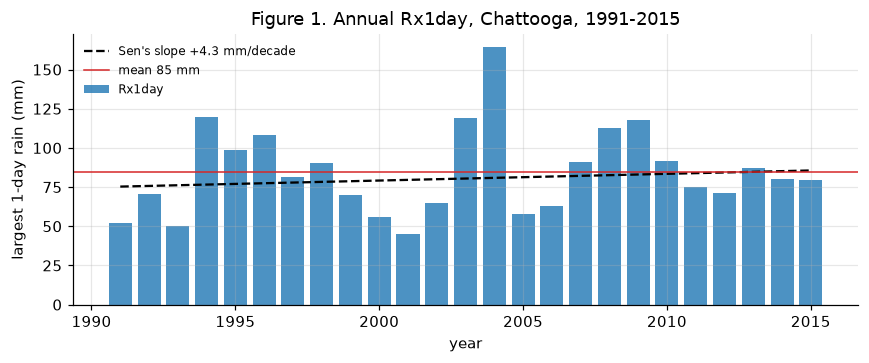

In [4]:
yrs = ind.index.to_numpy()
tau, p_mk = stats.kendalltau(yrs, ind["Rx1day"])
sen = stats.theilslopes(ind["Rx1day"], yrs)
print(f"Rx1day: Mann-Kendall tau = {tau:+.2f}, p = {p_mk:.2f};  Sen's slope = {10*sen.slope:+.1f} mm per decade")

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(yrs, ind["Rx1day"], color="tab:blue", alpha=0.8, label="Rx1day")
ax.plot(yrs, sen.intercept + sen.slope * yrs, "k--", label=f"Sen's slope {10*sen.slope:+.1f} mm/decade")
ax.axhline(ind["Rx1day"].mean(), color="tab:red", lw=1, label=f"mean {ind['Rx1day'].mean():.0f} mm")
ax.set(xlabel="year", ylabel="largest 1-day rain (mm)", title="Figure 1. Annual Rx1day, Chattooga, 1991-2015")
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

The Sen slope is positive (about +4 mm per decade) but Mann-Kendall gives $p \approx 0.56$, far above 0.05: in 25 years the year-to-year swings (from 45 mm in 2001 to 164 mm in 2004) hide any trend this small. Detecting a change in extremes needs long records or many stations together, which is why the IPCC statements on heavier rain rest on global networks, not on one gauge.

## 3) The annual maximum series

To study floods we need one list of "flood" values. There are two ways to build it:

- **Annual maximum series (AMS):** take the single largest value of each year. It is simple, each year gives exactly one value, and the values are close to independent because they come from different years. Its weakness: a dry year still contributes its small maximum, and the second-largest flood of a very wet year is thrown away.
- **Peaks over threshold (POT, or partial duration series):** keep every independent flood peak above a chosen level. It uses more of the data, but we must choose the threshold and make sure two peaks are not the same flood.

From here on we use the **AMS**, as Chow Chapter 12 and most design practice do.

Two notes on our record. We use **daily mean** discharge; the instantaneous peak of a small catchment is higher than the daily mean, so a design study would use instantaneous peaks from the gauging agency (in India, the Central Water Commission). And 25 years is a **short** record; Indian gauges of the CWC and IMD rainfall stations often offer longer ones.

n = 25 years;  mean 136.4 m3/s;  smallest 36.0 (2001);  largest 523.7 (2004, on 2004-09-17)


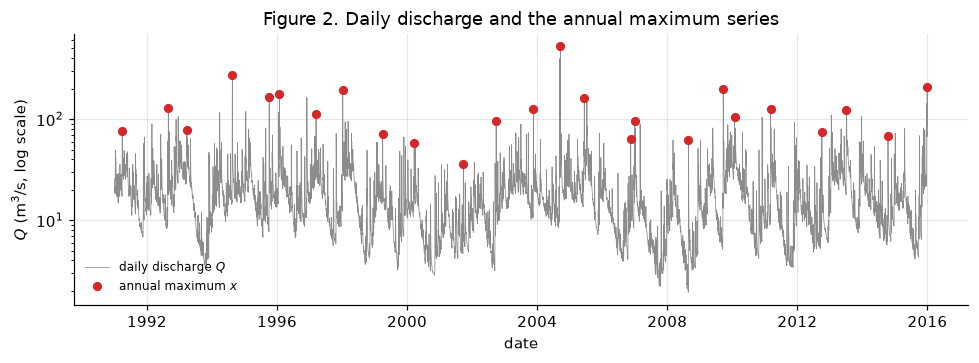

In [5]:
ams = Q.groupby(year).max()                    # annual maximum series, x, m3/s
ams.index.name = "year"
date_of_max = Q.groupby(year).idxmax()
n = len(ams)
print(f"n = {n} years;  mean {ams.mean():.1f} m3/s;  smallest {ams.min():.1f} ({ams.idxmin()});  largest {ams.max():.1f} ({ams.idxmax()}, on {date_of_max[ams.idxmax()].date()})")

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(Q.index, Q, lw=0.5, color="0.55", label="daily discharge $Q$")
ax.plot(date_of_max.values, ams.values, "o", color="tab:red", ms=5, label="annual maximum $x$")
ax.set_yscale("log")
ax.set(xlabel="date", ylabel="$Q$ (m$^3$/s, log scale)", title="Figure 2. Daily discharge and the annual maximum series")
ax.legend(frameon=False, fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

## 4) Return period, plotting position and risk

**Exceedance probability and return period.** If $p$ is the chance that the annual maximum reaches or exceeds a level $x_T$ in any one year, the average waiting time between such years is

$$
T = \frac{1}{p}, \qquad p = P(X \ge x_T) = \frac{1}{T}.
$$

A flood with $p = 0.02$ is the 50-year flood. This needs the years to be independent and the climate to stay the same (stationary); Lecture 25 asks what happens when it does not.

**Plotting position.** For a record we do not know $p$, we estimate it. Sort the $n$ annual maxima from largest to smallest and give rank $m = 1$ to the largest. The **Weibull plotting position** (one of the formulas listed by Chow, Section 12.3) is

$$
p = \frac{m}{n+1}, \qquad T = \frac{n+1}{m}.
$$

*Why $n+1$ and not $n$?* With $m/n$ the smallest value would get $p = 1$, a certainty that every future year will beat it, and the largest would get $T = n$ exactly. Dividing by $n + 1$ leaves room for future floods larger than anything seen: the largest of 25 years gets $T = 26$ years, not "the largest possible".

**Probability plot.** We plot $x$ against $T$ on an axis stretched so that rare floods spread out. Here the stretch is the Gumbel reduced variate $y_T = -\ln[\ln(T/(T-1))]$; Lecture 25 shows why a Gumbel distribution plots as a straight line on this axis.

**Risk over a design life.** A bridge stands for $N$ years. The chance that the $T$-year flood does **not** occur in one year is $1 - 1/T$; for $N$ independent years it is $(1 - 1/T)^N$. So the chance that it occurs **at least once** is

$$
R = 1 - \left(1 - \frac{1}{T}\right)^{N}.
$$

Turned around, the return period needed to keep the risk at $R$ over $N$ years is $T = 1/[1 - (1 - R)^{1/N}]$.

## 5) Worked example (by hand)

```{admonition} Problem
:class: tip
A small Himalayan river gauge (made-up numbers) has 10 years of annual maximum discharge, in m$^3$/s:

| Year | 2011 | 2012 | 2013 | 2014 | 2015 | 2016 | 2017 | 2018 | 2019 | 2020 |
|:--|--:|--:|--:|--:|--:|--:|--:|--:|--:|--:|
| $x$ | 420 | 285 | 540 | 350 | 710 | 300 | 465 | 385 | 615 | 330 |

(a) Rank the values and find the Weibull plotting position $p$ and the empirical return period $T$ of each.
(b) What is the chance that the 2015 flood (710 m$^3$/s) is equalled or exceeded at least once in the next 5 years?
(c) A bridge has a design life of $N = 50$ years and is built for the 100-year flood. What is the risk $R$?
(d) What $T$ keeps the risk at 10 % over the same 50 years?
```

**(a) Rank and plotting position.** *Why:* we have no formula for $p$ yet, so we let the record speak: a value beaten only once in 10 years is roughly a 1-in-10 event. Here $n = 10$, so $n + 1 = 11$. Sort from largest down, $m = 1$ for the largest:

| $m$ | Year | $x$ (m$^3$/s) | $p = m/11$ | $T = 11/m$ (years) |
|--:|:--|--:|--:|--:|
| 1 | 2015 | 710 | 1/11 = 0.091 | 11/1 = 11.0 |
| 2 | 2019 | 615 | 2/11 = 0.182 | 11/2 = 5.50 |
| 3 | 2013 | 540 | 3/11 = 0.273 | 11/3 = 3.67 |
| 4 | 2017 | 465 | 4/11 = 0.364 | 11/4 = 2.75 |
| 5 | 2011 | 420 | 5/11 = 0.455 | 11/5 = 2.20 |
| 6 | 2018 | 385 | 6/11 = 0.545 | 11/6 = 1.83 |
| 7 | 2014 | 350 | 7/11 = 0.636 | 11/7 = 1.57 |
| 8 | 2020 | 330 | 8/11 = 0.727 | 11/8 = 1.38 |
| 9 | 2016 | 300 | 9/11 = 0.818 | 11/9 = 1.22 |
| 10 | 2012 | 285 | 10/11 = 0.909 | 11/10 = 1.10 |

Check: $p$ goes up by $1/11 = 0.091$ each row, and $p \times T = 1$ in every row. The median of the 10 values, $(420 + 385)/2 = 402.5$ m$^3$/s, sits between $T = 2.20$ and $T = 1.83$, close to the "2-year flood".

**(b)** *Why:* the 2015 flood is our estimate of an 11-year flood, and "next 5 years" is a design life of $N = 5$.

$$
R = 1 - \left(1 - \tfrac{1}{11}\right)^{5} = 1 - (0.90909)^{5} = 1 - 0.62092 = 0.379.
$$

Step by step: $0.90909^2 = 0.82645$, $0.82645^2 = 0.68301$, $0.68301 \times 0.90909 = 0.62092$. A flood at least as big as 2015 has about a 38 % chance of coming back within 5 years.

**(c)** $R = 1 - (1 - 0.01)^{50} = 1 - 0.99^{50}$. With logarithms: $50 \ln 0.99 = 50 \times (-0.0100503) = -0.50252$, and $e^{-0.50252} = 0.60501$, so $R = 1 - 0.60501 = 0.395$. A "100-year" bridge has about a **40 % chance** of meeting its design flood during its life.

**(d)** $(1 - R)^{1/N} = 0.90^{1/50}$: $\ln 0.90 = -0.105361$, divided by 50 gives $-0.0021072$, and $e^{-0.0021072} = 0.997895$. Then $1/T = 1 - 0.997895 = 0.0021050$ and $T = 1/0.0021050 = 475$ years. To be 90 % sure of not seeing the design flood in 50 years, design for about the **475-year** flood.

**Answer.** The largest flood (710 m$^3$/s) has $p = 0.091$, $T = 11$ years, and the smallest (285 m$^3$/s) has $p = 0.909$, $T = 1.1$ years; (b) $R = 0.379$; (c) $R = 0.395$; (d) $T = 475$ years. The same small AMS is used again in Lecture 25 to fit a Gumbel distribution.

In [6]:
# The hand example in code; the same numbers are on sheets PlotPos and Risk of lec24_worked_examples.xlsx
x_hand = pd.Series([420, 285, 540, 350, 710, 300, 465, 385, 615, 330], index=range(2011, 2021), name="x")

def plotting_positions(x):
    """Rank from the largest (m = 1), Weibull p = m/(n+1) and T = 1/p (Chow, Section 12.3)."""
    s = x.sort_values(ascending=False)
    m = np.arange(1, len(s) + 1)
    p = m / (len(s) + 1)
    return pd.DataFrame({"year": s.index, "x": s.values, "m": m, "p": p, "T": 1 / p})

def risk(T, N):
    """Chance that the T-year event is equalled or exceeded at least once in N years."""
    return 1 - (1 - 1 / T) ** N

print(plotting_positions(x_hand).round(3).to_string(index=False))
print(f"(b) R(T = 11, N = 5)   = {risk(11, 5):.3f}")
print(f"(c) R(T = 100, N = 50) = {risk(100, 50):.3f}")
print(f"(d) T for R = 0.10, N = 50: {1 / (1 - 0.90 ** (1 / 50)):.1f} years")

 year   x  m     p      T
 2015 710  1 0.091 11.000
 2019 615  2 0.182  5.500
 2013 540  3 0.273  3.667
 2017 465  4 0.364  2.750
 2011 420  5 0.455  2.200
 2018 385  6 0.545  1.833
 2014 350  7 0.636  1.571
 2020 330  8 0.727  1.375
 2016 300  9 0.818  1.222
 2012 285 10 0.909  1.100
(b) R(T = 11, N = 5)   = 0.379
(c) R(T = 100, N = 50) = 0.395
(d) T for R = 0.10, N = 50: 475.1 years


## 6) Plotting positions and the probability plot for the Chattooga

The same three lines of code now rank the 25 Chattooga annual maxima. The largest daily flow, 524 m$^3$/s on 17 September 2004, came when the remains of Hurricane Ivan crossed the southern Appalachians ten days after those of Hurricane Frances had soaked the ground; it gets $m = 1$, $p = 1/26 = 0.038$ and $T = 26$ years.

 year       x  m     p      T   y_T
 2004 523.737  1 0.038 26.000 3.239
 1994 272.060  2 0.077 13.000 2.525
 2015 208.928  3 0.115  8.667 2.099
 2009 200.153  4 0.154  6.500 1.789
 1998 195.906  5 0.192  5.200 1.544
...
 year      x  m     p     T    y_T
 2000 57.469 24 0.923 1.083 -0.942
 2001 35.954 25 0.962 1.040 -1.181


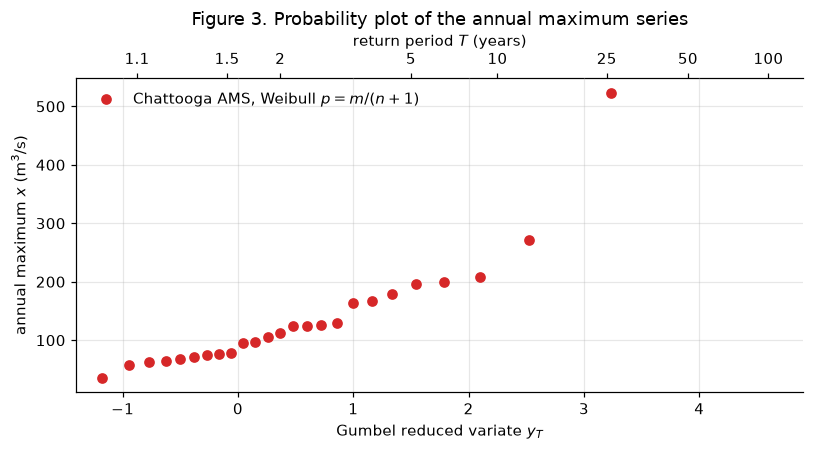

In [7]:
pp = plotting_positions(ams)
pp["y_T"] = -np.log(np.log(pp["T"] / (pp["T"] - 1)))          # Gumbel reduced variate, the plot axis
print(pp.head(5).round(3).to_string(index=False)); print("...")
print(pp.tail(2).round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(pp["y_T"], pp["x"], "o", color="tab:red", label="Chattooga AMS, Weibull $p = m/(n+1)$")
ax.set(xlabel="Gumbel reduced variate $y_T$", ylabel="annual maximum $x$ (m$^3$/s)",
       title="Figure 3. Probability plot of the annual maximum series")
T_ticks = np.array([1.1, 1.5, 2, 5, 10, 25, 50, 100])
top = ax.secondary_xaxis("top", functions=(lambda y: y, lambda y: y))
top.set_xticks(-np.log(np.log(T_ticks / (T_ticks - 1)))); top.set_xticklabels([f"{t:g}" for t in T_ticks])
top.set_xlabel("return period $T$ (years)")
ax.set_xlim(-1.4, 4.9); ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

**Reading Figure 3.** The points rise slowly from the 1-year to the 10-year end and then the 2004 flood jumps far above the rest. The plot answers "how big is a flood with $T$ = 5 years?" directly, around 195 m$^3$/s (the 1998 value has $T = 5.2$). It cannot answer "how big is the 100-year flood?": the largest plotting position of a 25-year record is $T = 26$, and one unusual year decides where the top of the curve is. To go further we need a distribution fitted through all 25 points and extended, which is the **flood frequency analysis** of Lecture 25. The same plot, with fitted lines on top, will be Figure 1 there.

risk R for design life N:
  T     N=10   N=25   N=50   N=100
  10  0.651  0.928  0.995  1.000
  25  0.335  0.640  0.870  0.983
  50  0.183  0.397  0.636  0.867
 100  0.096  0.222  0.395  0.634
 500  0.020  0.049  0.095  0.181


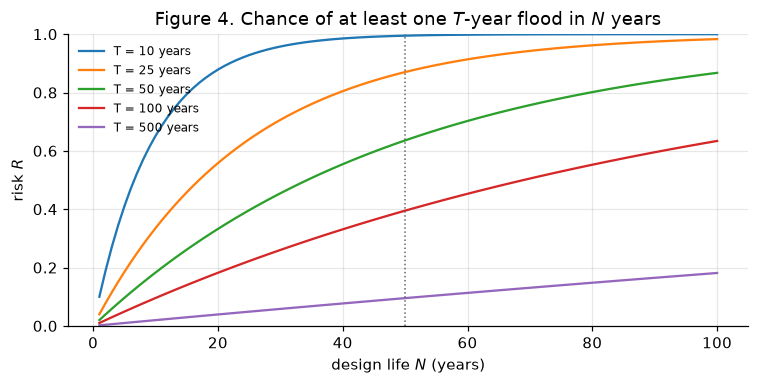

In [8]:
T_list = [10, 25, 50, 100, 500]
N_list = np.arange(1, 101)
print("risk R for design life N:\n  T     N=10   N=25   N=50   N=100")
for T in T_list:
    print(f"{T:4d}  " + "  ".join(f"{risk(T, N):.3f}" for N in (10, 25, 50, 100)))

fig, ax = plt.subplots(figsize=(7, 3.6))
for T in T_list:
    ax.plot(N_list, risk(T, N_list), label=f"T = {T} years")
ax.axvline(50, color="0.4", ls=":", lw=1)
ax.set(xlabel="design life $N$ (years)", ylabel="risk $R$", ylim=(0, 1),
       title="Figure 4. Chance of at least one $T$-year flood in $N$ years")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

**Reading Figure 4.** Over a 50-year life (dotted line) the 10-year flood is almost certain to occur ($R = 0.995$), the 50-year flood is more likely than not ($R = 0.636$), and even the 100-year flood has a 40 % chance. Only the 500-year flood stays below 10 % ($R = 0.095$). This is why the design return period of a structure is usually much longer than its life, and why the choice of $T$ is a decision about acceptable risk, not only a hydrological number (Lecture 25, Section 7).

## Summary

- Floods are riverine, flash, pluvial (urban), coastal, glacial lake outburst, or dam-break and debris floods; India has recent examples of each. Risk combines the hazard with exposure and vulnerability.
- ETCCDI indices (Rx1day, Rx5day, R20mm, R95pTOT, CDD, CWD) summarise heavy rain and dry spells year by year. For the Chattooga, Rx1day averages 85 mm and shows no significant trend in 25 years.
- The annual maximum series keeps the largest flow of each year. Rank it from the largest, $p = m/(n+1)$ and $T = (n+1)/m$.
- A $T$-year flood has a $1/T$ chance in every year. Over a design life of $N$ years the risk is $R = 1 - (1 - 1/T)^N$: 0.395 for $T = 100$ and $N = 50$.
- Empirical points stop at $T \approx n + 1$; estimating rarer floods needs a fitted distribution (Lecture 25).

## Check your understanding

1. A town has had no "50-year flood" for 49 years. Is it more likely to have one next year than a town that had one last year? Why?
2. Why does the Weibull formula divide by $n + 1$? What return period does it give the largest value of a 40-year record?
3. Why is Rx5day more useful than Rx1day for the Brahmaputra, and Rx1day more useful for Mumbai's storm drains?

## Try it yourself

- Add an eleventh year with $x = 800$ m$^3$/s to the hand example (in the workbook or the code). How do the $p$ and $T$ of the 2015 flood change?
- Build a peaks-over-threshold series for the Chattooga: keep every day above 150 m$^3$/s that is the largest within 7 days either side. How many peaks per year do you get?
- Compute the ETCCDI indices for the first and last 12 years of the record and compare their means.

```{note} Sources
Written for **CE524 Applied Hydroclimatology**. Return period, exceedance probability, risk and plotting positions follow Chow, V. T., Maidment, D. R., & Mays, L. W. (1988). *Applied Hydrology*. McGraw-Hill, **Chapter 12** (Sections 12.1 and 12.3). Extreme-rainfall indices follow Zhang, X., Alexander, L., Hegerl, G. C., Jones, P., Klein Tank, A., Peterson, T. C., Trewin, B., & Zwiers, F. W. (2011). Indices for monitoring changes in extremes based on daily temperature and precipitation data. *WIREs Climate Change, 2*, 851&ndash;870. The explanations, the hand example and its numbers, the workbook and the figures were made for this course and do not reproduce the book's text, tables or examples.

**Data.** `data/chattooga_daily.csv`: Chattooga River near Clayton, GA (USGS 02177000), 536 km$^2$; rainfall from Daymet v4 (Thornton et al., 2022) and discharge from USGS NWIS (public domain). The hand-example data are made up. Related lectures: 7 and 10 (Chattooga record, routing), 15 (Mann-Kendall and Sen's slope), 17 (distributions), 25 (flood frequency analysis).

Text under CC BY-SA 4.0, code additionally under the MIT License; full attribution in [CREDITS.md](https://github.com/drvivekhydro/hydroclimatology/blob/main/CREDITS.md).
```